# O3 Alignment and Sampling QC

This notebook reads cached full-cohort QC tables. It does not rebuild columns, resample MD, or modify pipeline outputs. Depth is defined from pial (0) to white (1).

In [28]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RESULTS_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/results/qc/"
    "full_cohort_spatial_scale/option3_qc/cohort"
)
MANIFEST = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/code/"
    "cortical_trajectory_analysis/manifests/"
    "full_300_subject_manifest.csv"
)
REPO_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / '.git').exists()
)
sys.path.insert(0, str(REPO_ROOT))
from qc.publication_style import (
    FIGURE_WIDTH_IN, PALETTE, save_publication_figure,
    set_publication_style, style_axes,
)

sns.set_theme(style="ticks", context="notebook")
set_publication_style()
FIGURE_DIR = RESULTS_ROOT / 'figures'

## 1. Method summary
O3 maps each fsaverage vertex to a native spherical triangle, interpolates native pial and white endpoints with barycentric weights, and samples 21 MD values along the resulting subject-specific column.

## 2. Input manifest
The denominator is the full input-complete cohort. Missing or failed subjects remain visible in the status table.

In [29]:
manifest = pd.read_csv(MANIFEST)
status = pd.read_csv(RESULTS_ROOT / "full_cohort_status.csv")
display(status["status"].value_counts().rename_axis("status").to_frame("n_subjects"))

,n_subjects
status,
complete,325
failed,2


## 3. Mapping and barycentric-weight QC
This section checks triangle lookup, source vertex IDs, weight bounds, weight sums, and closest-point reconstruction error. It does not establish T1-to-DWI registration quality.

In [30]:
qc = pd.read_csv(RESULTS_ROOT / "option3_mapping_qc_subject_hemi.csv")
mapping_columns = [
    "mapping_valid_percentage",
    "n_out_of_range_weights",
    "mapping_error_p95",
]
display(qc[mapping_columns].describe())

,mapping_valid_percentage,n_out_of_range_weights,mapping_error_p95
count,650.0,650.0,6.500000e+02
mean,100.0,0.0,1.542612e-16
std,0.0,0.0,7.086657e-18
min,100.0,0.0,1.359740e-16
25%,100.0,0.0,1.570092e-16
50%,100.0,0.0,1.570092e-16
75%,100.0,0.0,1.570092e-16
max,100.0,0.0,1.570092e-16


## 4. Coverage
Mapping, geometric-column, in-bounds, finite-MD, and complete-profile coverage are separate quantities. Complete profiles require all 21 depths to pass. Coverage is calculated within the analysis mask. A bilateral coverage threshold of 95% is used here as an explicit QC review flag, consistent with the prespecified Figure 5 feature-eligibility threshold. It does not by itself constitute a registration failure or retroactively change the Figure 4 cohort.


In [ ]:
COVERAGE_REVIEW_THRESHOLD_PCT = 95.0

# n_complete_valid_profile is a full-mesh count, so it must not be divided
# by n_analysis_mask_vertices. Recover the analysis-mask count from the
# cached analysis-mask percentage before pooling hemispheres.
coverage_hemi = qc[[
    'subject_id', 'hemisphere', 'n_analysis_mask_vertices',
    'complete_valid_profile_pct_analysis_mask',
]].copy()
coverage_hemi['n_complete_valid_profile_analysis_mask'] = (
    coverage_hemi['complete_valid_profile_pct_analysis_mask']
    * coverage_hemi['n_analysis_mask_vertices'] / 100
).round().astype(int)
coverage = coverage_hemi.groupby('subject_id', as_index=False).agg(
    valid=('n_complete_valid_profile_analysis_mask', 'sum'),
    denominator=('n_analysis_mask_vertices', 'sum'),
)
coverage['coverage_pct'] = 100 * coverage['valid'] / coverage['denominator']
coverage['below_95pct_review_threshold'] = (
    coverage['coverage_pct'] < COVERAGE_REVIEW_THRESHOLD_PCT
)
registration_exclusions = pd.read_csv(
    REPO_ROOT / 'manifests' / 'figure4_registration_qc_exclusions.csv',
    dtype={'subject_id': str},
)
coverage = coverage.merge(
    registration_exclusions[['subject_id', 'qc_status', 'qc_reason']],
    on='subject_id', how='left', validate='one_to_one',
)
coverage['figure4_registration_qc'] = coverage['qc_status'].fillna('retained')
coverage = coverage.sort_values('coverage_pct').reset_index(drop=True)

coverage_threshold_summary = pd.DataFrame({
    'criterion': ['<90%', '<95% (review flag)', '<99%'],
    'n_subjects': [
        int(coverage['coverage_pct'].lt(90).sum()),
        int(coverage['coverage_pct'].lt(COVERAGE_REVIEW_THRESHOLD_PCT).sum()),
        int(coverage['coverage_pct'].lt(99).sum()),
    ],
})
display(coverage_threshold_summary)
display(
    coverage.loc[
        coverage['below_95pct_review_threshold'],
        [
            'subject_id', 'valid', 'denominator', 'coverage_pct',
            'figure4_registration_qc', 'qc_reason',
        ],
    ].style.format({'coverage_pct': '{:.2f}%'})
)

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 3.1))
ax.scatter(range(len(coverage)), coverage['coverage_pct'], s=12, color=PALETTE['blue'])
ax.axhline(99, color=PALETTE['reference'], linestyle='--', linewidth=0.9)
ax.axhline(
    COVERAGE_REVIEW_THRESHOLD_PCT, color=PALETTE['gray'],
    linestyle=':', linewidth=0.8, label='95% review threshold',
)
ax.set(xlabel='Subjects ordered by coverage', ylabel='Complete profiles (%)')
ax.legend(frameon=True, loc='lower right', facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
style_axes(ax, grid=True)
fig.tight_layout()
save_publication_figure(fig, FIGURE_DIR / 'option3_complete_profile_coverage')
plt.show()


## 5. Zero-length columns
Endpoint distance below 1e-6 mm is classified as zero length. Full-mesh and analysis-mask rates are shown separately.

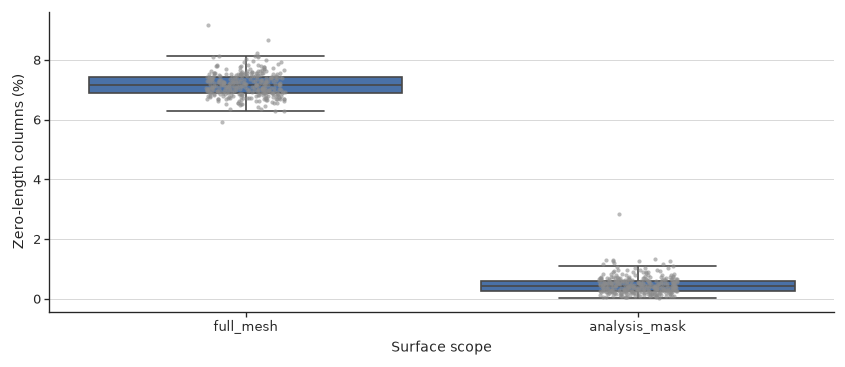

In [32]:
zero = qc.groupby("subject_id", as_index=False).agg(
    full_mesh=("zero_length_pct_full_mesh", "mean"),
    analysis_mask=("zero_length_pct_analysis_mask", "mean"),
)
zero_long = zero.melt(id_vars="subject_id", var_name="scope", value_name="percent")
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 3.1))
sns.boxplot(data=zero_long, x="scope", y="percent", showfliers=False, ax=ax, color=PALETTE['blue'])
sns.stripplot(data=zero_long, x="scope", y="percent", ax=ax, color=PALETTE['gray'], size=2.5, alpha=0.6)
ax.set(xlabel='Surface scope', ylabel='Zero-length columns (%)')
style_axes(ax, grid=True)
fig.tight_layout()
save_publication_figure(fig, FIGURE_DIR / 'option3_zero_length_columns')
plt.show()

## 6. DWI out-of-bounds sampling
OOB is evaluated after transforming T1 column points into zero-based DWI voxel coordinates and before interpolation.

## 7. Invalid MD by depth
OOB, nonfinite, exact-zero, and near-zero values are reported separately across the pial-to-white axis.

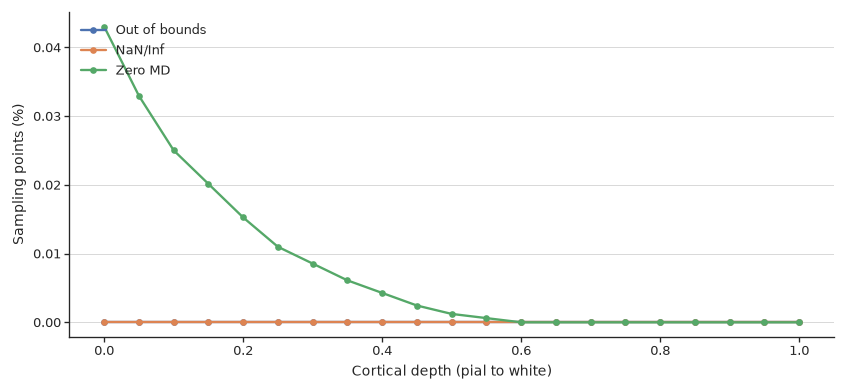

In [33]:
depth_qc = pd.read_csv(RESULTS_ROOT / "option3_invalid_md_by_depth.csv")
depth_summary = depth_qc.groupby("depth_fraction_pial_to_white", as_index=False)[[
    "point_oob_percentage",
    "point_nonfinite_md_percentage",
    "point_zero_md_percentage",
]].median()
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 3.3))
for column, label in {
    "point_oob_percentage": "Out of bounds",
    "point_nonfinite_md_percentage": "NaN/Inf",
    "point_zero_md_percentage": "Zero MD",
}.items():
    ax.plot(
        depth_summary["depth_fraction_pial_to_white"],
        depth_summary[column],
        marker="o",
        markersize=3,
        label=label,
    )
ax.set(xlabel="Cortical depth (pial to white)", ylabel="Sampling points (%)")
ax.legend(frameon=True, loc='upper left', facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
style_axes(ax, grid=True)
fig.tight_layout()
save_publication_figure(fig, FIGURE_DIR / 'option3_invalid_md_by_depth')
plt.show()

## 8. Mixed-label boundary analysis
Labels are categorical and are not interpolated. The triangle composition, target-label support, and distance to the fixed fsaverage DK boundary are QC measurements.

In [34]:
label_columns = [
    "valid_label_triangle_percentage",
    "mixed_label_triangle_percentage",
    "noncortical_triangle_percentage",
    "mixed_boundary_hops_median",
]
display(qc[label_columns].describe())

,valid_label_triangle_percentage,mixed_label_triangle_percentage,noncortical_triangle_percentage,mixed_boundary_hops_median
count,650.000000,650.000000,650.000000,650.000000
mean,92.424039,3.379359,7.575961,3.006154
std,0.465423,0.140408,0.465423,1.280393
min,89.925050,3.007776,5.989917,1.000000
25%,92.134953,3.289144,7.262027,2.000000
50%,92.461945,3.373677,7.538055,3.000000
75%,92.737973,3.471027,7.865047,4.000000
max,94.010083,4.525702,10.074950,7.000000


## 9. Column length and FreeSurfer thickness
High agreement supports geometric plausibility, but it does not imply that Euclidean endpoint distance and FreeSurfer thickness are identical measures.

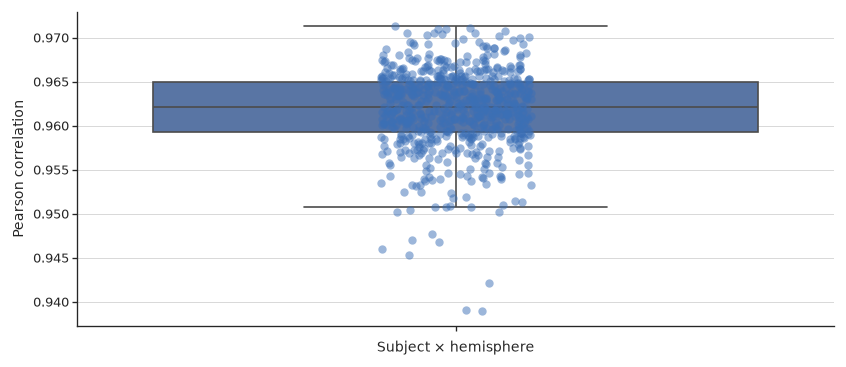

In [35]:
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 3.1))
sns.boxplot(data=qc, y="length_thickness_pearson_r", showfliers=False, ax=ax)
sns.stripplot(
    data=qc,
    y="length_thickness_pearson_r",
    color=PALETTE['blue'],
    alpha=0.5,
    ax=ax,
)
ax.set(ylabel="Pearson correlation", xlabel="Subject × hemisphere")
style_axes(ax, grid=True)
fig.tight_layout()
save_publication_figure(fig, FIGURE_DIR / 'option3_length_thickness_correlation')
plt.show()

## 10. T1-DWI registration
bbregister cost ranks cases for visual review. Automatic outliers are not automatically excluded.

In [36]:
registration = pd.read_csv(RESULTS_ROOT / "registration_cost_by_subject.csv")
registration_columns = [
    "bbregister_mincost",
    "robust_z",
    "automatic_cost_outlier",
]
display(registration[registration_columns].describe(include="all"))

,bbregister_mincost,robust_z,automatic_cost_outlier
count,325.000000,325.000000,325
unique,NaN,NaN,2
top,NaN,NaN,False
freq,NaN,NaN,303
mean,0.143230,0.569780,NaN
std,0.061292,1.764829,NaN
min,0.066462,-1.640683,NaN
25%,0.106246,-0.495142,NaN
50%,0.123442,0.000000,NaN
75%,0.160343,1.062528,NaN


## 11. Method agreement
Method agreement uses only subjects with complete O2-Column, O2-FS, and O3 outputs. Missing O2 outputs are not O3 failures.

## 12. Subject exclusion and final summary
Final exclusions require an explicit reviewed reason. This notebook reports requested, successful, failed, incomplete, and excluded counts without silently changing the denominator.

## Publication figure

The four primary O3 geometry and sampling checks are assembled below as a single 180-mm-wide figure. The panel descriptions belong in the manuscript caption.

In [ ]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(FIGURE_WIDTH_IN, 5.15))
grid = GridSpec(2, 2, figure=fig, hspace=0.42, wspace=0.34)

ax = fig.add_subplot(grid[0, 0])
ax.scatter(range(len(coverage)), coverage['coverage_pct'], s=10, color=PALETTE['blue'])
ax.axhline(99, color=PALETTE['reference'], linestyle='--', linewidth=0.9)
ax.axhline(95, color=PALETTE['gray'], linestyle=':', linewidth=0.8)
ax.set(xlabel='Subjects ordered by coverage', ylabel='Complete profiles (%)')
style_axes(ax, grid=True)

ax = fig.add_subplot(grid[0, 1])
sns.boxplot(data=zero_long, x='scope', y='percent', showfliers=False, ax=ax, color=PALETTE['blue'])
sns.stripplot(data=zero_long, x='scope', y='percent', ax=ax, color=PALETTE['gray'], size=2.2, alpha=0.55)
ax.set(xlabel='Surface scope', ylabel='Zero-length columns (%)')
style_axes(ax, grid=True)

ax = fig.add_subplot(grid[1, 0])
for column, label, color in (
    ('point_oob_percentage', 'Out of bounds', PALETTE['blue']),
    ('point_nonfinite_md_percentage', 'NaN/Inf', PALETTE['orange']),
    ('point_zero_md_percentage', 'Zero MD', PALETTE['gray']),
):
    ax.plot(depth_summary['depth_fraction_pial_to_white'], depth_summary[column],
            marker='o', markersize=3, color=color, label=label)
ax.set(xlabel='Cortical depth (pial to white)', ylabel='Sampling points (%)')
ax.legend(frameon=True, loc='upper left', facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
style_axes(ax, grid=True)

ax = fig.add_subplot(grid[1, 1])
sns.boxplot(data=qc, y='length_thickness_pearson_r', showfliers=False, ax=ax, color=PALETTE['blue'])
sns.stripplot(data=qc, y='length_thickness_pearson_r', ax=ax, color=PALETTE['gray'], size=2.2, alpha=0.5)
ax.set(xlabel='Subject × hemisphere', ylabel='Length–thickness Pearson r')
style_axes(ax, grid=True)

save_publication_figure(fig, FIGURE_DIR / 'option3_alignment_sampling_qc')
plt.show()